## How to Approach Machine Learning Projects


![](https://i.imgur.com/kKdAALX.png)

In this tutorial, we'll explore a step-by-step process for approaching ML problems:

1. Understand the business requirements and the nature of the available data.
2. Classify the problem as supervised/unsupervised and regression/classification.
3. Download, clean & explore the data and create new features that may improve models.
4. Create training/test/validation sets and prepare the data for training ML models.
5. Create a quick & easy baseline model to evaluate and benchmark future models.
6. Pick a modeling strategy, train a model, and tune hyperparameters to achieve optimal fit.
7. Experiment and combine results from multiple strategies to get a better result.
8. Interpret models, study individual predictions, and present your findings. 

In [1]:
!pip install opendatasets --upgrade --quiet

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import opendatasets as od

%matplotlib inline

sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

## Step 1 - Understand Business Requirements & Nature of Data

<p align="center">
  <img src="https://i.imgur.com/63XEArk.png" width="700">
</p>

Most machine learning models are developed to solve real-world problems. Before building any model, it is essential to understand the business objectives, available data, and expected outcomes. A clear understanding of the problem helps determine whether machine learning is appropriate and guides the selection of suitable models and evaluation metrics.

### Understanding the Big Picture

The first step in any machine learning project is to read the available documentation, communicate with stakeholders, and gather information about the problem domain.

Key questions to consider include:

1. What is the business problem being solved?
2. Why is solving this problem important, and what impact will it have?
3. How is the problem currently handled without machine learning?
4. Who will use the model's predictions, and how will they fit into existing business processes?
5. How much historical data is available, and how was it collected?
6. What features are present in the dataset? Does it include historical values of the target variable?
7. Are there any known data quality issues such as missing values, incorrect entries, or inconsistent units?
8. Are sample records representative of the overall dataset?
9. Where is the data stored, and how can it be accessed?
10. What assumptions, constraints, and risks should be considered?

Gathering answers to these questions helps establish the feasibility of the project and creates a clear roadmap for building an effective machine learning solution.

### Rossmann Store Sales Case Study

#### Business Problem

Rossmann operates more than 1,000 drug stores across Europe and aims to accurately forecast daily sales for each store.

#### Why is this Problem Important?

Accurate sales forecasting can help:

- Improve inventory planning
- Optimize workforce scheduling
- Support promotional campaigns
- Reduce operational costs
- Improve decision-making and profitability

#### Current Solution

Traditionally, store managers rely on historical trends, intuition, and manual forecasting techniques to estimate future sales.

#### End Users

The model's predictions can be used by:

- Store managers
- Business analysts
- Inventory planners
- Marketing teams
- Executive management

#### Available Data

The dataset contains:

- Historical daily sales records
- Customer counts
- Store information
- Promotion details
- Holiday indicators
- Competition-related information
- Date and time attributes

#### Target Variable

```python
Sales

## Step 2 - Classify the problem as supervised/unsupervised & regression/classification

<img src="https://i.imgur.com/rqt2A7F.png" width="640">

Here's the landscape of machine learning([source](https://medium.datadriveninvestor.com/machine-learning-in-10-minutes-354d83e5922e)):

<img src="https://miro.medium.com/max/842/1*tlQwBmbL6RkuuFq8OPJofw.png" width="640">



Here are the topics in machine learning that we're studying in this course ([source](https://vas3k.com/blog/machine_learning/)): 

<img src="https://i.imgur.com/VbVFAsg.png" width="640">



____
### Loss Functions and Evaluation Metrics

Once the type of machine learning problem has been identified, it is important to select appropriate loss functions and evaluation metrics.

#### Loss Functions

Loss functions are used during model training to measure the difference between the model's predictions and the actual target values. The learning algorithm continuously adjusts model parameters to minimize the loss.

Examples:

- Regression:
  - Mean Squared Error (MSE)
  - Mean Absolute Error (MAE)

- Classification:
  - Binary Cross Entropy (Log Loss)
  - Categorical Cross Entropy

#### Evaluation Metrics

Evaluation metrics are used after training to assess how well a model performs on unseen data. They help compare different models and determine whether a model satisfies the project requirements.

Examples:

- Regression:
  - RMSE (Root Mean Squared Error)
  - MAE (Mean Absolute Error)
  - R² Score

- Classification:
  - Accuracy
  - Precision
  - Recall
  - F1-Score
  - ROC-AUC

### Difference Between Loss Functions and Evaluation Metrics

| Loss Function | Evaluation Metric |
|--------------|------------------|
| Used during model training | Used after model training |
| Optimized by the algorithm | Interpreted by humans |
| Guides parameter updates | Measures overall model performance |
| Focused on minimizing prediction errors | Focused on assessing predictive quality |

### Rossmann Store Sales Prediction

**Problem Type:** Supervised Learning (Regression)

**Loss Function:**
- Mean Squared Error (MSE)

**Evaluation Metric:**
- Root Mean Squared Error (RMSE)
- Root Mean Squared Percentage Error (RMSPE)

Since the target variable (*Sales*) is a continuous numerical value, regression metrics are appropriate.

### Breast Cancer Identification

**Problem Type:** Supervised Learning (Binary Classification)

**Loss Function:**
- Binary Cross Entropy (Log Loss)

**Evaluation Metrics:**
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

For medical diagnosis, Recall is especially important because failing to identify a malignant tumor may have serious consequences.

### Key Takeaway

Loss functions help the model learn during training, whereas evaluation metrics help humans determine how well the trained model performs on unseen data.

## Step 3 - Download, clean & explore the data and create new features

<img src="https://i.imgur.com/0f7foe7.png" width="640">

### Downloading Data

There may be different sources to get the data:

* CSV files
* SQL databases
* Raw File URLs
* Kaggle datasets 
* Google Drive
* Dropbox
* etc.

Identify the right tool/library to get the data. 

For the Rossmann Store Sales prediction dataset, we'll use the `opendatasets` library. Make sure to [accept the competition rules](https://www.kaggle.com/c/rossmann-store-sales/rules) before executing the following cell.

In [3]:
import os

os.listdir('rossmann-store-sales')

['sample_submission.csv', 'store.csv', 'test.csv', 'train.csv']

In [4]:
ross_df = pd.read_csv('rossmann-store-sales/train.csv', low_memory=False)

ross_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
store_df = pd.read_csv(
    'rossmann-store-sales/store.csv' , low_memory=False
)

store_df.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


We can merge the two data frames to get a richer set of features for each row of the training set. 

In [6]:
merged_df = ross_df.merge(store_df , how='left' , on='Store')
merged_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [7]:
merged_df.shape

(1017209, 18)

The dataset also contains a test set.

In [8]:

test_df=pd.read_csv('rossmann-store-sales/test.csv')

merged_test_df = test_df.merge(store_df , how='left' , on='Store')

merged_test_df.head()


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN


### Cleaning Data

The first step is to check the column data types and identify if there are any null values.

In [9]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  object 
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  object 
 10  Assortment                 1017209 non-null  object 
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionO

It appears there are some null values

In [10]:
round(merged_df.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.43,321.91,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,4.00,2.00,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.82,3849.93,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.15,464.41,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.83,0.38,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.38,0.49,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.18,0.38,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,1014567.0,5430.09,7715.32,20.0,710.0,2330.0,6890.0,75860.0
CompetitionOpenSinceMonth,693861.0,7.22,3.21,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,693861.0,2008.69,5.99,1900.0,2006.0,2010.0,2013.0,2015.0


In [11]:
merged_df.duplicated().sum()

0

Let's also parse the date column

In [12]:
merged_df['Date'] = pd.to_datetime(merged_df.Date)

In [13]:
merged_test_df['Date'] = pd.to_datetime(merged_test_df.Date)

In [14]:
merged_df.Date.min() , merged_df.Date.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [15]:
merged_test_df.Date.min() , merged_test_df.Date.max()

(Timestamp('2015-08-01 00:00:00'), Timestamp('2015-09-17 00:00:00'))

## Exploratory Data Analysis and Visualization

Exploratory Data Analysis (EDA) is an important step in the machine learning workflow. It helps us understand the dataset, identify patterns, detect potential issues, and generate insights that can improve model performance.

### Objectives of Exploratory Data Analysis

- Study the distribution of individual features (normal, skewed, uniform, exponential, etc.).
- Detect anomalies, outliers, missing values, or incorrect data entries.
- Understand the relationship between input features and the target variable.
- Identify trends, patterns, and correlations within the dataset.
- Gain business and domain-specific insights from the data.
- Discover opportunities for feature engineering and data preprocessing.
- Determine which variables may be most useful for prediction.
- Validate assumptions before building machine learning models.

### Why EDA is Important

EDA helps answer questions such as:

- Which features have the strongest influence on the target variable?
- Are there missing values that need to be handled?
- Are there any unusual observations or outliers?
- Do certain variables follow seasonal or temporal trends?
- Can additional features be created to improve predictive performance?

By performing EDA, we can make informed decisions about data cleaning, feature engineering, preprocessing techniques, and model selection.

<AxesSubplot:xlabel='Sales', ylabel='Count'>

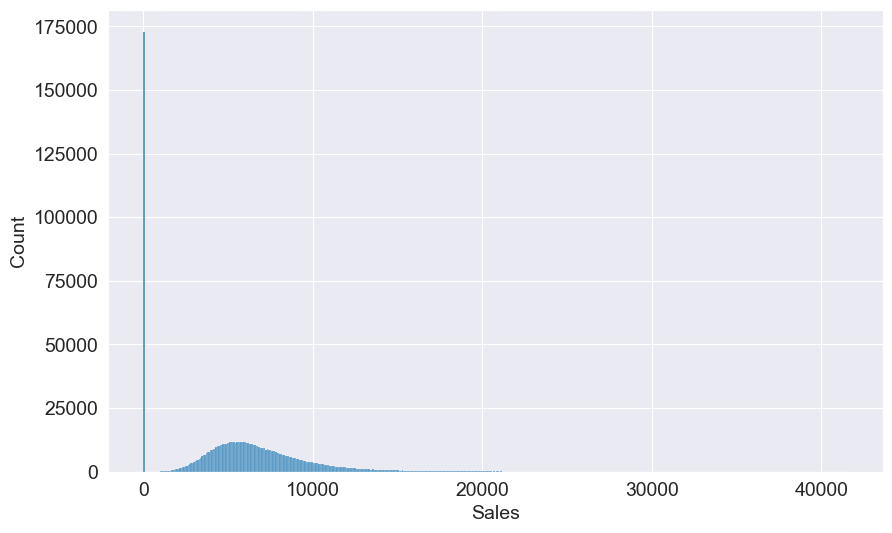

In [16]:
sns.histplot(data = merged_df , x = 'Sales')

To make our modeling simple, let's simply exclude the dates when the store was closed (we can handle it as a special case while making predictions. 

In [17]:
merged_df = merged_df[merged_df.Open == 1].copy()

<AxesSubplot:xlabel='Sales', ylabel='Count'>

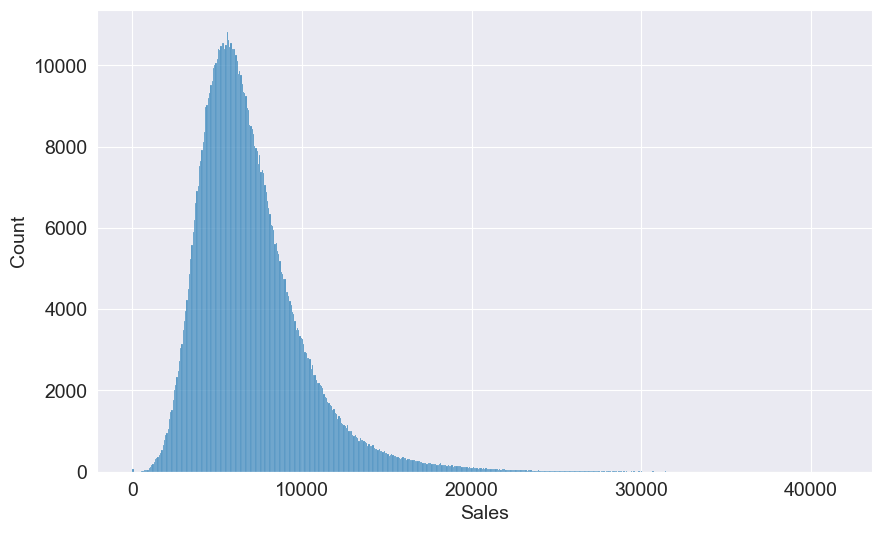

In [18]:
sns.histplot(data = merged_df , x='Sales')

### Why are Sales 0 on so Many Dates?

The histogram shows a large concentration of observations at `Sales = 0`. This suggests that many stores reported no sales on certain days.

A likely explanation is that the stores were closed on those dates. When a store is closed, no transactions can take place, resulting in zero sales.

To verify this hypothesis, we can examine the `Open` column and compare the number of closed-store records with the number of zero-sales records.

In [19]:
merged_df.Open.value_counts()

Open
1    844392
Name: count, dtype: int64

In [20]:
merged_df.Sales.value_counts()[0]

54

Let's explore some other columns

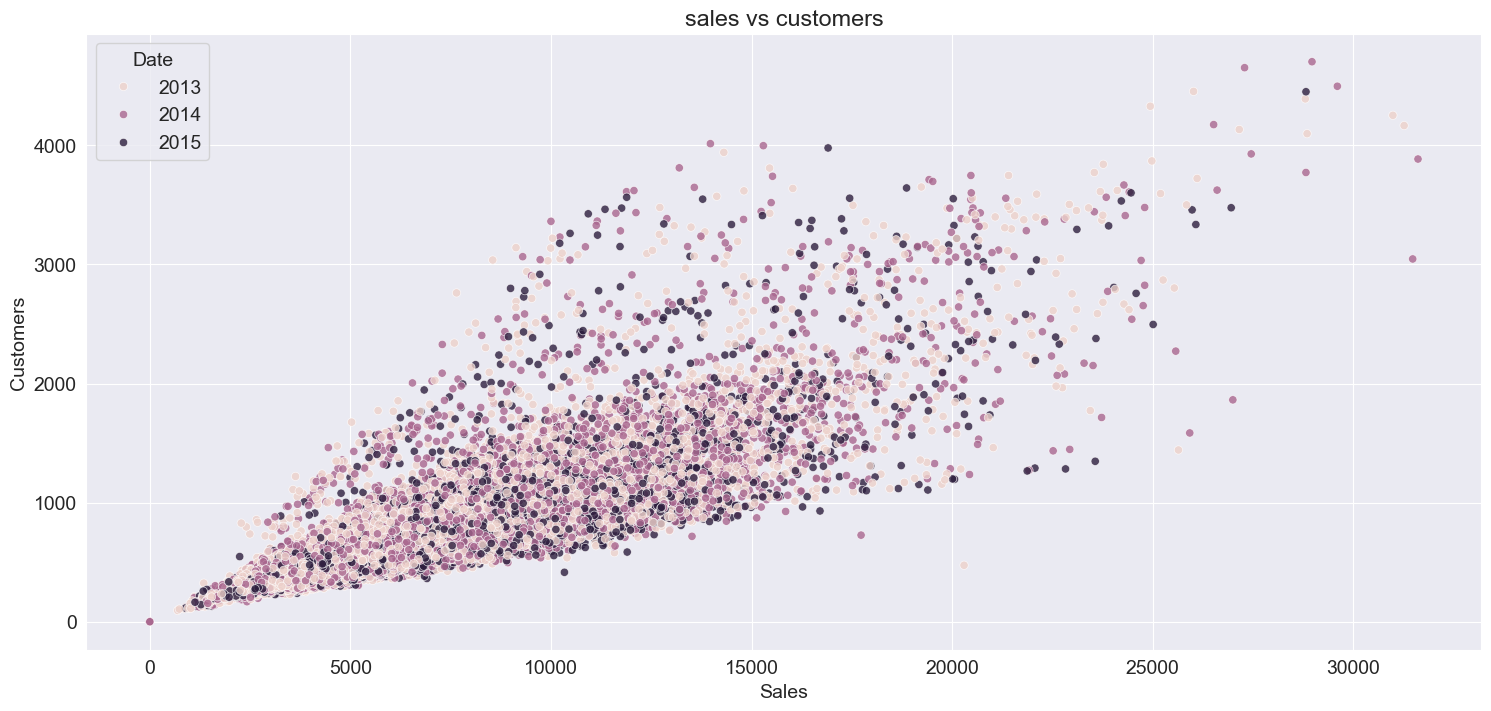

In [21]:
plt.figure(figsize=(18 , 8))
temp_df = merged_df.sample(40000)

sns.scatterplot(x=temp_df.Sales , y=temp_df.Customers , hue = temp_df.Date.dt.year , alpha=0.8)
plt.title('sales vs customers')
plt.show()

### Sales vs Customers

The scatter plot shows a strong positive relationship between the number of customers and store sales.

### Observations

- As the number of customers increases, sales generally increase.
- Stores with fewer customers tend to generate lower sales.
- Stores with a larger number of customers tend to achieve higher sales.
- The relationship appears approximately linear, indicating that customer count is a strong predictor of sales.
- A few outliers are visible where stores generated unusually high sales or attracted exceptionally large numbers of customers.
- The distribution is consistent across the years 2013, 2014, and 2015, suggesting that the relationship between customers and sales remained relatively stable over time.

### Insights

The number of customers is one of the strongest drivers of store sales. This relationship suggests that customer traffic has a direct impact on revenue generation and can provide valuable information when forecasting future sales.

### Conclusion

There is a strong positive correlation between customers and sales. Stores with higher customer footfall tend to generate significantly greater sales, making customer count an important feature for understanding and predicting sales performance.

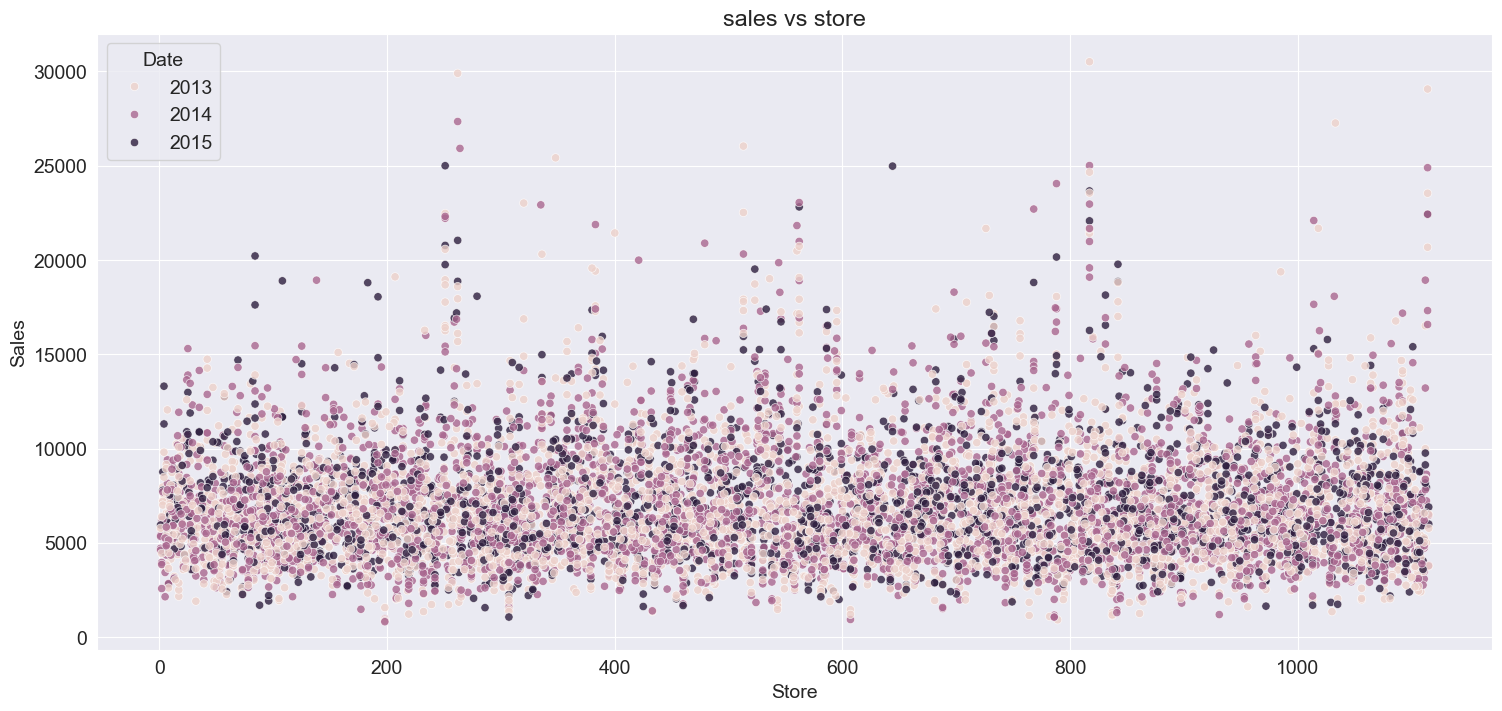

In [22]:
plt.figure(figsize=(18 , 8))

temp_df =merged_df.sample(10000)
sns.scatterplot(x=temp_df.Store , y=temp_df.Sales , hue = temp_df.Date.dt.year , alpha=0.8)
plt.title('sales vs store')
plt.show()

### Sales vs Store

The scatter plot shows daily sales across different Rossmann stores.

### Observations

- The x-axis represents Store IDs rather than a numerical feature.
- Each point represents the sales of a particular store on a specific date.
- Sales vary considerably between stores.
- Some stores consistently achieve higher sales than others.
- No clear linear relationship exists because Store IDs are simply identifiers and do not carry numerical meaning.

### Insights

The variation in sales across stores suggests that store-specific characteristics such as location, store type, assortment, customer traffic, promotions, and competition may influence sales performance.

### Conclusion

Store ID acts as a categorical identifier rather than a numerical variable. The plot highlights differences in sales performance among stores and suggests that store-specific information can be valuable for sales forecasting.

<AxesSubplot:xlabel='DayOfWeek', ylabel='Sales'>

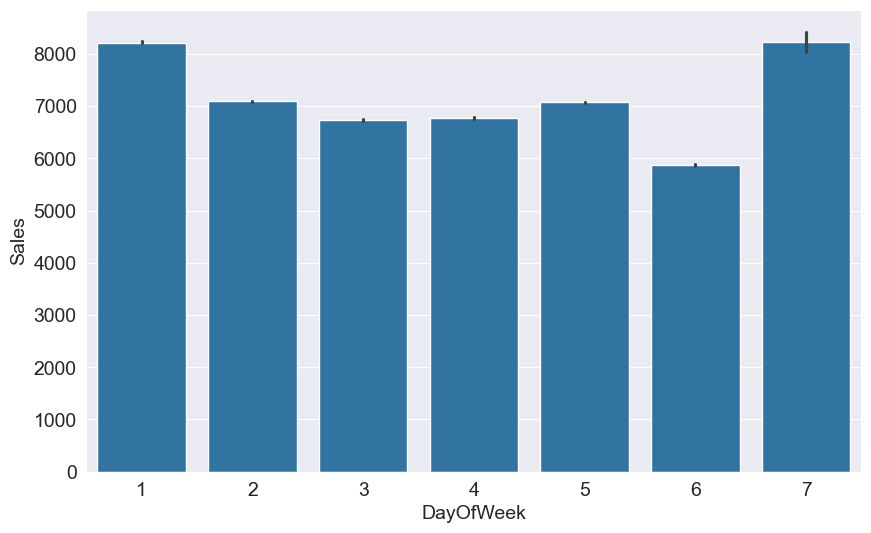

In [23]:
sns.barplot(data=merged_df , x='DayOfWeek' , y='Sales')

<AxesSubplot:xlabel='Promo', ylabel='Sales'>

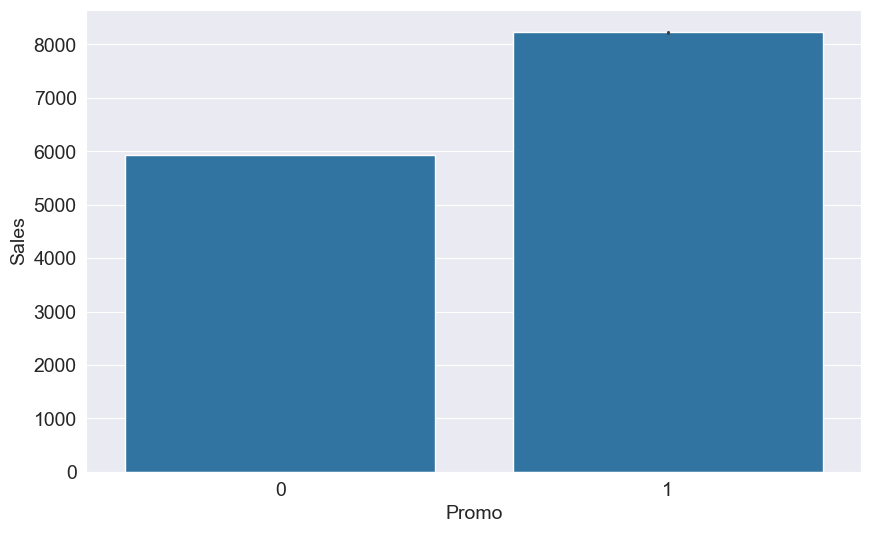

In [24]:
sns.barplot(data=merged_df, x='Promo', y='Sales')

In [25]:
merged_df.select_dtypes(include='number').corr()['Sales'].sort_values(ascending=False)

Sales                        1.000000
Customers                    0.823597
Promo                        0.368145
Promo2SinceWeek              0.095311
SchoolHoliday                0.038617
CompetitionOpenSinceYear     0.016101
Store                        0.007710
Promo2SinceYear             -0.034713
CompetitionDistance         -0.036396
CompetitionOpenSinceMonth   -0.043489
Promo2                      -0.127596
DayOfWeek                   -0.178736
Open                              NaN
Name: Sales, dtype: float64

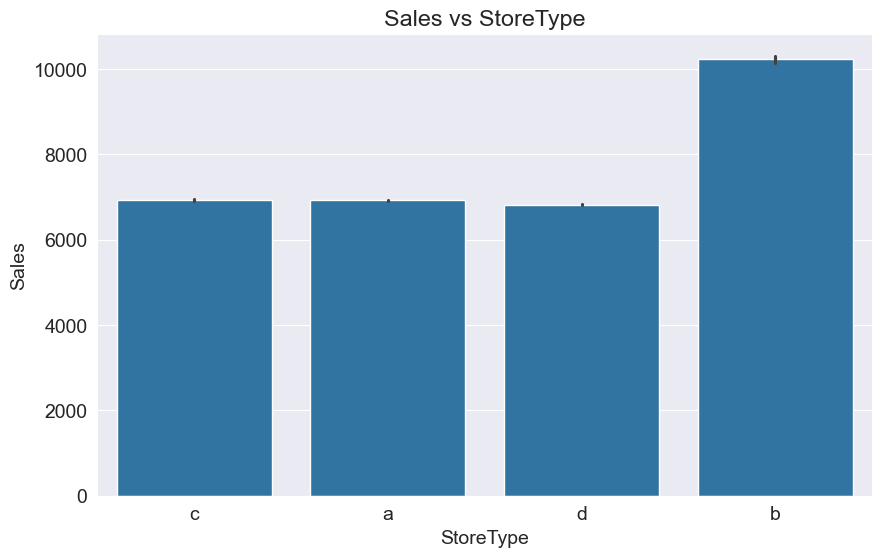

In [26]:
sns.barplot(data=merged_df , x='StoreType' , y='Sales')
plt.title('Sales vs StoreType')
plt.show()

#### Store Type vs Sales

The bar plot compares average sales across different store types.

### Observations

- Store Type **b** has the highest average sales, significantly outperforming other store categories.
- Store Types **a**, **c**, and **d** have relatively similar average sales.
- The differences in average sales suggest that store characteristics influence revenue generation.

### Insights

Store Type appears to be an important predictor of sales. The strong performance of Store Type **b** indicates that certain store formats may attract more customers or generate higher transaction values.

### Conclusion

Store Type has a noticeable relationship with sales and should be retained as an important feature for sales forecasting models.

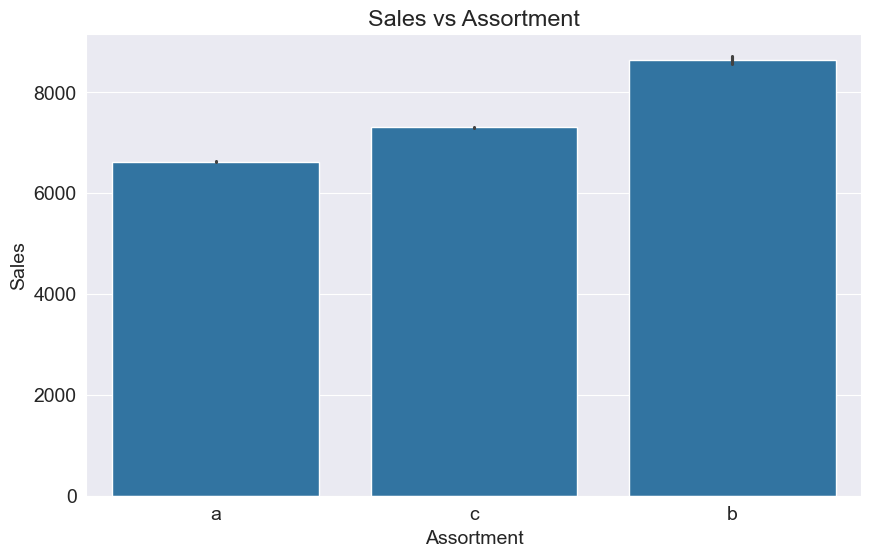

In [27]:
sns.barplot(data=merged_df , x='Assortment' , y='Sales')
plt.title('Sales vs Assortment')
plt.show()


#### Assortment vs Sales

The bar plot compares average sales across different assortment categories.

### Observations

- Stores with Assortment **b** achieve the highest average sales.
- Stores with Assortment **c** generate moderately high sales.
- Stores with Assortment **a** have the lowest average sales.
- Average sales increase as the assortment becomes more extensive.

### Insights

The product assortment offered by a store appears to have a significant impact on sales performance. Stores with a larger variety of products tend to generate higher revenue, likely because they attract more customers and offer more purchasing options.

### Conclusion

Assortment is an important feature for predicting sales. The clear differences in average sales across assortment categories suggest that product variety influences customer spending behavior and overall store performance.

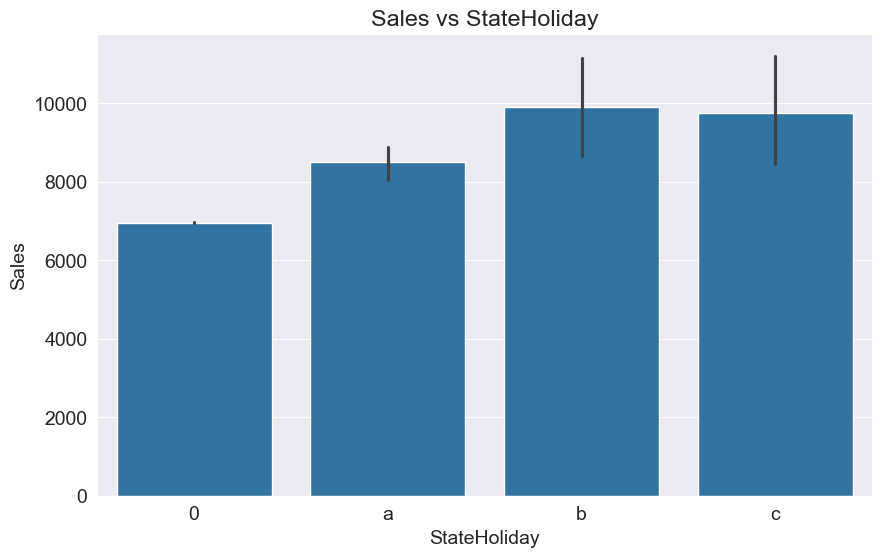

In [28]:
sns.barplot(data=merged_df , x='StateHoliday' , y='Sales')
plt.title('Sales vs StateHoliday')
plt.show()

#### State Holiday vs Sales

The bar plot compares average sales across different holiday categories.

### Observations

- Sales are highest during Easter holidays (b) and Christmas holidays (c).
- Public holidays (a) also exhibit higher average sales than non-holiday days.
- Non-holiday days (0) show the lowest average sales.
- Holiday categories have larger variability in sales, indicating that the effect of holidays differs across stores.

### Insights

Holidays appear to positively influence sales performance. Major holidays such as Easter and Christmas are associated with increased customer spending, resulting in higher revenue for stores that remain open.

### Conclusion

StateHoliday is an informative feature for sales prediction. The results suggest that holiday periods significantly affect customer purchasing behavior and should be included in forecasting models.

### Feature Engineering

Feature engineer is the process of creating new features (columns) by transforming/combining existing features or by incorporating data from external sources. 


For example, here are some features that can be extracted from the "Date" column:

1. Day of week
2. Day or month
3. Month
4. Year
5. Weekend/Weekday
6. Month/Quarter End


In [29]:
merged_df['Day'] = merged_df.Date.dt.day
merged_df['Month'] = merged_df.Date.dt.month
merged_df['Year'] = merged_df.Date.dt.year

In [30]:
merged_test_df['Day'] = merged_test_df.Date.dt.day
merged_test_df['Month'] = merged_test_df.Date.dt.month
merged_test_df['Year'] = merged_test_df.Date.dt.year

<AxesSubplot:xlabel='Year', ylabel='Sales'>

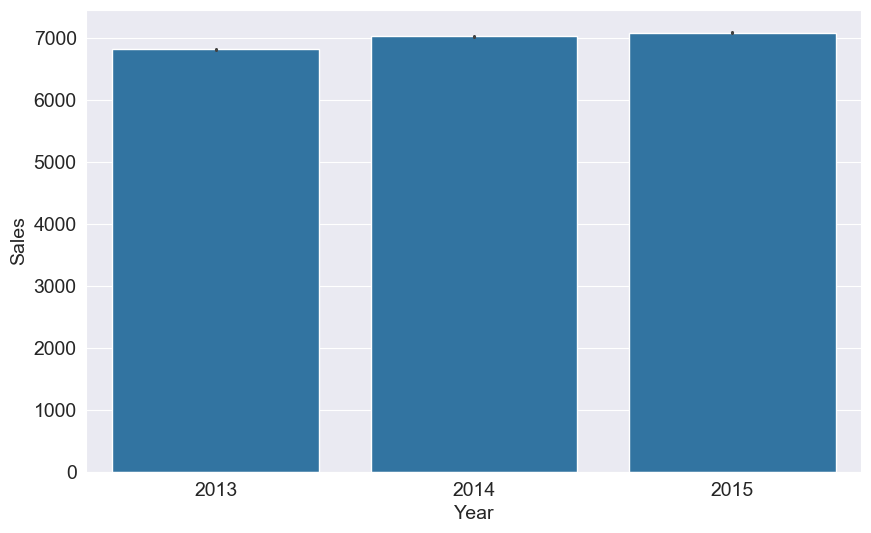

In [31]:
sns.barplot(data=merged_df , x="Year" , y='Sales')

<AxesSubplot:xlabel='Month', ylabel='Sales'>

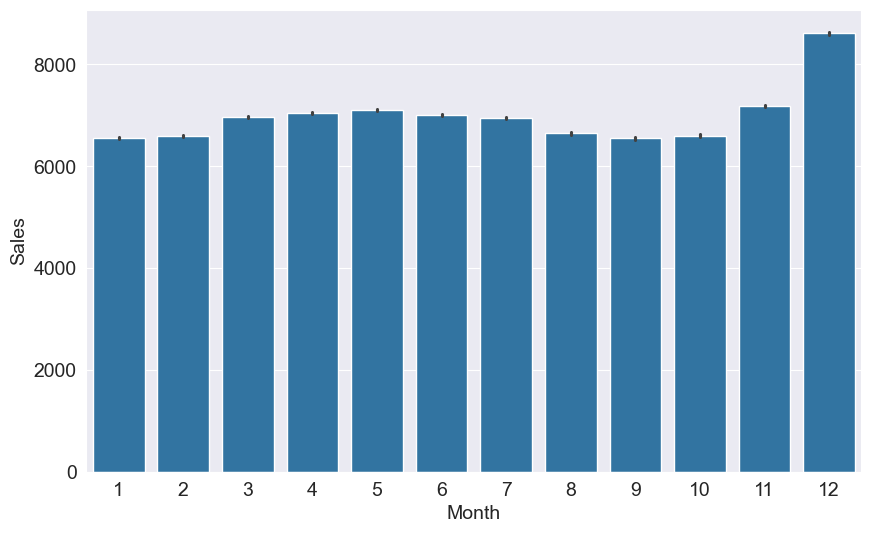

In [32]:
sns.barplot(data=merged_df , x='Month' , y='Sales')



Using date information, we can also create new current columns like: 

1. Weather on each day
2. Whether the date was a public holiday
3. Whether the store was running a promotion on that day.


> **EXERCISE**: Create new columns using the above ideas.

<AxesSubplot:xlabel='Weekend', ylabel='Sales'>

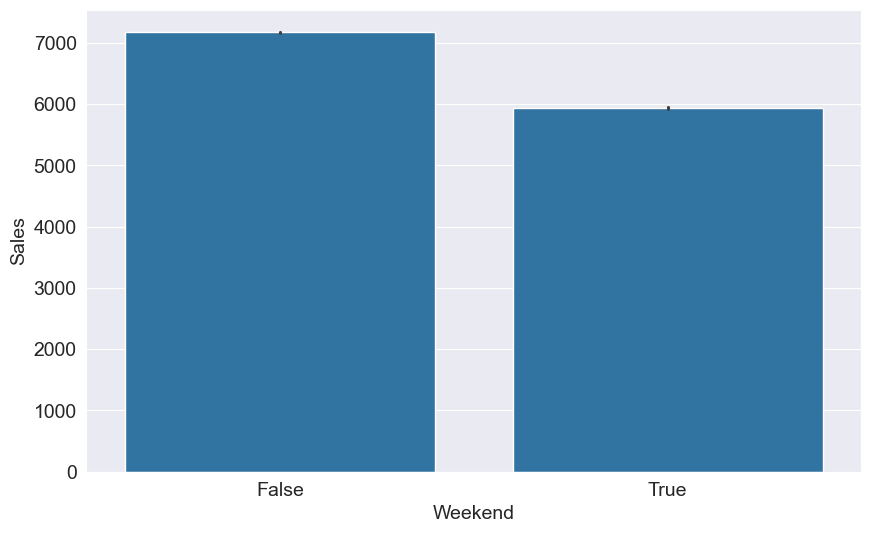

In [33]:
merged_df['Weekend'] = merged_df.Date.dt.day_of_week>=5
sns.barplot(data=merged_df , x='Weekend' , y='Sales')

<AxesSubplot:xlabel='IsHoliday', ylabel='Sales'>

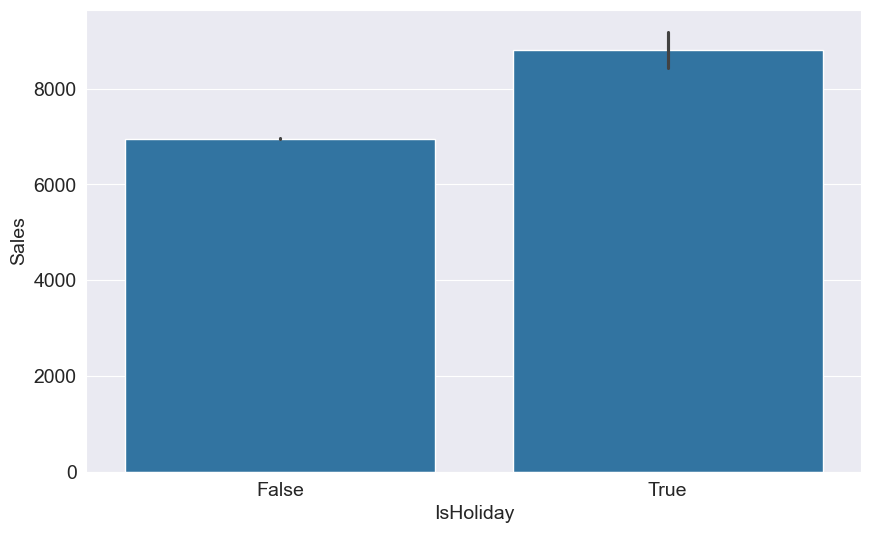

In [34]:
merged_df['IsHoliday'] = merged_df.StateHoliday != '0'
sns.barplot(data=merged_df , x="IsHoliday" , y="Sales")

<AxesSubplot:xlabel='Ispromo', ylabel='Sales'>

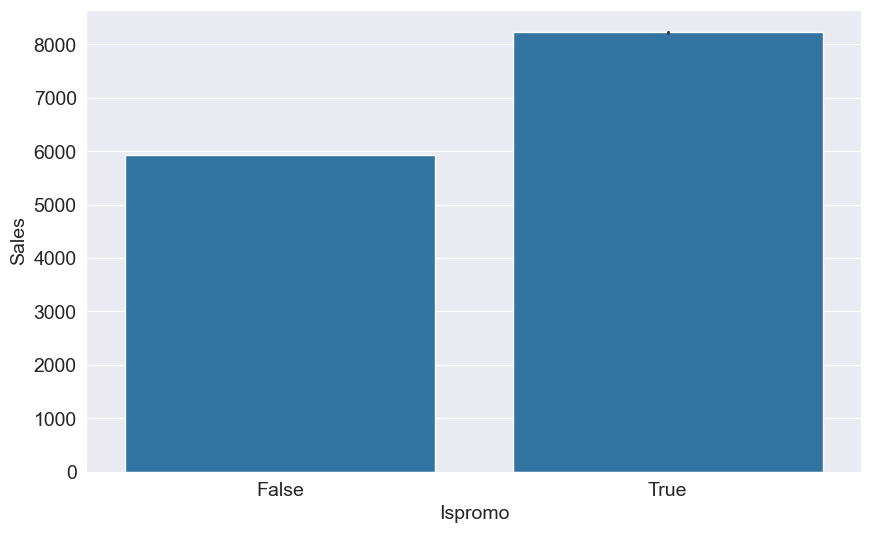

In [35]:
merged_df['Ispromo'] = merged_df.Promo != 0 
sns.barplot(data=merged_df , x="Ispromo" , y="Sales")

<AxesSubplot:xlabel='MonthEnd', ylabel='Sales'>

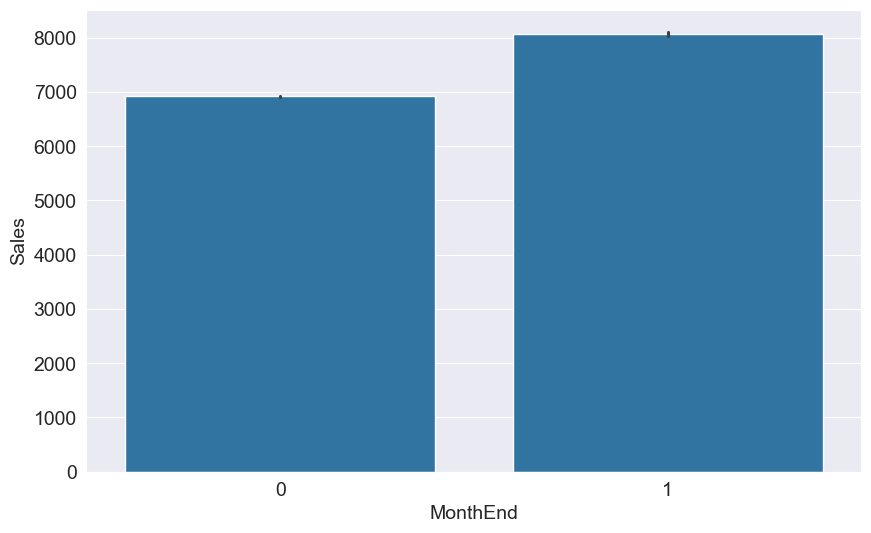

In [36]:
merged_df['MonthEnd'] = merged_df.Date.dt.is_month_end.astype(int)
sns.barplot(data=merged_df , x="MonthEnd" , y="Sales")

<AxesSubplot:xlabel='Quarter', ylabel='Sales'>

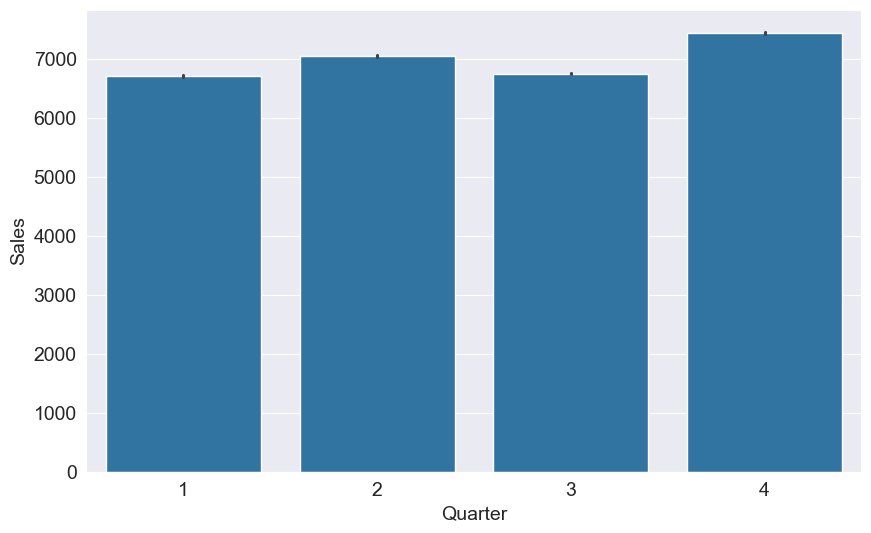

In [37]:
merged_df['Quarter'] = merged_df.Date.dt.quarter
sns.barplot(data=merged_df , x="Quarter" , y="Sales")

## Analysis of Engineered Features

### 1. Weekend vs Sales

Sales on weekdays are higher than sales on weekends.

**Observations:**
- Average weekday sales are approximately 7,100.
- Average weekend sales are approximately 5,900.
- Customer activity appears to be stronger during regular working days.

**Conclusion:**
The Weekend feature captures weekly shopping patterns and may help the model identify differences in customer behavior across the week.

---

### 2. Holiday vs Sales

Holiday periods are associated with higher average sales.

**Observations:**
- Non-holiday sales average around 6,900.
- Holiday sales average around 8,800.
- Customers tend to spend more during holidays and festive periods.

**Conclusion:**
Holiday information is an important feature because it captures increased demand during special occasions.

---

### 3. Promotion vs Sales

Promotions have the strongest positive effect on sales among the engineered features.

**Observations:**
- No-promotion sales average around 5,900.
- Promotion sales average around 8,200.
- Running promotions significantly increases store revenue.

**Conclusion:**
Promotional campaigns are highly effective in increasing sales and represent a critical feature for forecasting.

---

### 4. Month-End vs Sales

Sales are higher at the end of the month.

**Observations:**
- Non-month-end sales average around 6,900.
- Month-end sales average around 8,000.
- Customers may increase spending near salary payments or monthly purchasing cycles.

**Conclusion:**
The MonthEnd feature captures monthly purchasing behavior and contributes useful information for prediction.

---

### 5. Quarter vs Sales

Sales vary across different quarters of the year.

**Observations:**
- Quarter 4 has the highest average sales.
- Quarter 2 also performs relatively well.
- Quarter 1 and Quarter 3 show comparatively lower sales.

**Conclusion:**
Quarterly trends indicate the presence of seasonality in sales, making Quarter a useful feature for forecasting models.

---

## Overall Conclusion

The engineered features successfully capture important temporal and business patterns.

### Feature Impact Ranking

1. Promotion (Strongest Impact)
2. Holiday
3. Month-End
4. Quarter
5. Weekend

These features provide additional information beyond the original dataset and are likely to improve the performance of sales forecasting models.

_____ 
## Step 4 - Create a training/test/validation split and prepare the data for training

<img src="https://i.imgur.com/XZ9aP10.png" width="640">

### Train/Test/Validation Split

The data already contains a test set, which contains over one month of data after the end of the training set. We can apply a similar strategy to create a validation set. We'll the last 25% of rows for the validation set, after ordering by date

In [38]:
len(merged_df)

844392

In [39]:
train_size = int(.75 * len(merged_df))
train_size

633294

In [40]:
sorted_df = merged_df.sort_values(by='Date')
train_df , val_df = sorted_df[:train_size] , sorted_df[train_size:]

In [41]:
len(train_df) , len(val_df)

(633294, 211098)

In [42]:
train_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Promo2SinceYear,PromoInterval,Day,Month,Year,Weekend,IsHoliday,Ispromo,MonthEnd,Quarter
1017190,1097,2,2013-01-01,5961,1405,1,0,a,1,b,...,NaN,NaN,1,1,2013,False,True,False,0,1
1016179,85,2,2013-01-01,4220,619,1,0,a,1,b,...,NaN,NaN,1,1,2013,False,True,False,0,1
1016353,259,2,2013-01-01,6851,1444,1,0,a,1,b,...,NaN,NaN,1,1,2013,False,True,False,0,1
1016356,262,2,2013-01-01,17267,2875,1,0,a,1,b,...,NaN,NaN,1,1,2013,False,True,False,0,1
1016368,274,2,2013-01-01,3102,729,1,0,a,1,b,...,2013.0,"Jan,Apr,Jul,Oct",1,1,2013,False,True,False,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256632,745,3,2014-12-10,6897,657,1,0,0,0,a,...,2009.0,"Jan,Apr,Jul,Oct",10,12,2014,False,False,False,0,4
256642,756,3,2014-12-10,15736,2292,1,0,0,0,a,...,2011.0,"Jan,Apr,Jul,Oct",10,12,2014,False,False,False,0,4
256634,747,3,2014-12-10,7444,608,1,0,0,0,c,...,NaN,NaN,10,12,2014,False,False,False,0,4
256633,746,3,2014-12-10,5207,474,1,0,0,0,d,...,2011.0,"Mar,Jun,Sept,Dec",10,12,2014,False,False,False,0,4


In [43]:
train_df.Date.min() , train_df.Date.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2014-12-10 00:00:00'))

In [44]:
val_df.Date.min() , val_df.Date.max()

(Timestamp('2014-12-10 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [45]:
merged_test_df.Date.min() , merged_test_df.Date.max()

(Timestamp('2015-08-01 00:00:00'), Timestamp('2015-09-17 00:00:00'))

In [46]:
train_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year', 'Weekend',
       'IsHoliday', 'Ispromo', 'MonthEnd', 'Quarter'],
      dtype='object')

### Input and Target columns

Let's also identify input and target columns. Note that we can't use the no. of customers as an input, because this information isn't available beforehand. Also, we needn't use all the available columns, we can start out with just a small subset.

In [47]:
input_cols = ['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'StoreType', 'Assortment', 'Day', 'Month', 'Year']

In [48]:
target_col = 'Sales'

In [49]:
merged_df[input_cols].nunique()

Store           1115
DayOfWeek          7
Promo              2
StateHoliday       4
StoreType          4
Assortment         3
Day               31
Month             12
Year               3
dtype: int64

In [50]:
train_inputs = train_df[input_cols].copy()
train_targets = train_df[target_col].copy()

In [51]:
val_inputs = val_df[input_cols].copy()
val_targets = val_df[target_col].copy()


In [52]:
test_inputs = merged_test_df[input_cols].copy()
#Test Data doesnot have target column so we will not create test_targets

In [53]:
numeric_cols = ['Store' , 'Day' , 'Month' , 'Year']
categorical_cols = ['DayOfWeek' , 'Promo' , 'StateHoliday' , 'StoreType' , 'Assortment']

### Imputation, Scaling and Encode

Let's impute missing data from numeric columns and scale the values to the $(0, 1)$ range. 

In [54]:
from sklearn.impute import SimpleImputer

In [55]:
imputer = SimpleImputer(strategy='mean').fit(train_inputs[numeric_cols])

In [56]:
train_inputs[numeric_cols] = imputer.transform(train_inputs[numeric_cols])
val_inputs[numeric_cols] = imputer.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols] = imputer.transform(test_inputs[numeric_cols])

Note that this step wasn't necessary for the store sales dataset, as there were no null values. Also, we can apply a different imputation strategy to different columns depending on their distributions (e.g. mean for normally distribute and median for exponentially distributed).

Let's also scale the values to the $(0, 1)$ range.

In [57]:
from sklearn.preprocessing import MinMaxScaler

In [58]:
scaler = MinMaxScaler().fit(train_inputs[numeric_cols])

In [59]:
train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols])
val_inputs[numeric_cols] = scaler.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols] = scaler.transform(test_inputs[numeric_cols])

In [60]:
from sklearn.preprocessing import OneHotEncoder

In [61]:
encoder = OneHotEncoder(
    sparse_output = False,
    handle_unknown = 'ignore'
).fit(train_inputs[categorical_cols])
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))

In [62]:
train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
val_inputs[encoded_cols] = encoder.transform(val_inputs[categorical_cols])
test_inputs[encoded_cols] = encoder.transform(test_inputs[categorical_cols])

Imputer.fit()  → Learn averages
Scaler.fit()   → Learn min and max
Encoder.fit()  → Learn categories

Let's now extract out the numeric data.

In [63]:
X_train = train_inputs[numeric_cols + encoded_cols]
X_val = val_inputs[numeric_cols + encoded_cols]
X_test = test_inputs[numeric_cols + encoded_cols]

## Step 5 - Create quick & easy baseline models to benchmark future models

<img src="https://i.imgur.com/1DLgiEz.png" width="640">


A quick baseline model helps establish the minimum score any ML model you train should achieve.


### Fixed/Random Guess

Let's define a model that always returns the mean value of Sales as the prediction.

In [64]:
def return_mean(inputs):
    return np.full(len(inputs) , merged_df.Sales.mean())

In [65]:
train_preds = return_mean(X_train)

In [66]:
train_preds 

array([6955.51429076, 6955.51429076, 6955.51429076, ..., 6955.51429076,
       6955.51429076, 6955.51429076])

Let's evaluate this to using the RMSE score.

In [67]:
from sklearn.metrics import mean_squared_error


In [68]:
mean_squared_error(train_targets , train_preds , squared=False)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


3082.450443277419

In [69]:
mean_squared_error(return_mean(X_val) , val_targets , squared=False) 

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


3168.6033635047716

The model is off by about $3000 on average.Let's try another model, which makes a random guess between the lowest and highest sale.

In [70]:
print(merged_df.Sales.max()) 
print(merged_df.Sales.min())


41551
0


In [71]:
def guess_random(inputs):
    lo , hi = merged_df.Sales.min() , merged_df.Sales.max()
    return np.random.randint(lo , hi , len(inputs))

In [72]:
train_preds = guess_random(X_train)
train_preds

array([16253, 40718, 35851, ..., 10550, 14055, 16774])

In [73]:
mean_squared_error(train_preds, train_targets, squared=False)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


18614.22549512194

In [74]:
mean_squared_error(guess_random(X_val), val_targets, squared=False)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


18398.864614357128

Clearly, this model is much worse.

> **EXERCISE**: Write a function that implements the following strategy:
>
> 1. If the store is closed, return 0.
> 2. If the store is open, return the average sales of the store for the current month in the previous year.
>
> Find the validation set score for this strategy.

In [75]:
sales_by_store_month =( merged_df.groupby(['Store' , 'Year' , 'Month'])['Sales'].mean())

def predict_sales(row):
    if row['Open'] == 0:
        return 0

    prev_year = row['Year'] -1

    try : 
        return sales_by_store_month.loc[row['Store'] , prev_year , row['Month']]
    except KeyError:
        return merged_df.Sales.mean()


In [76]:
val_preds = val_df.apply(predict_sales, axis=1)

In [77]:
from sklearn.metrics import mean_squared_error

mean_squared_error(
    val_targets,
    val_preds,
    squared=False
)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


1999.4313114461465

### Baseline ML model

Let's train a simple `LinearRegression` model, with no customization.

In [78]:
from sklearn.linear_model import LinearRegression


In [79]:
linreg = LinearRegression().fit(X_train , train_targets)


`model.fit` uses the following workflow for training the model ([source](https://www.deepnetts.com/blog/from-basic-machine-learning-to-deep-learning-in-5-minutes.html)):

1. We initialize a model with random parameters (weights & biases).
2. We pass some inputs into the model to obtain predictions.
3. We compare the model's predictions with the actual targets using the loss function.  
4. We use an optimization technique (like least squares, gradient descent etc.) to reduce the loss by adjusting the weights & biases of the model
5. We repeat steps 1 to 4 till the predictions from the model are good enough.


<img src="https://www.deepnetts.com/blog/wp-content/uploads/2019/02/SupervisedLearning.png" width="480">
The we have fit the model, the model can now be used to make predictions. Note that the parameters of the model will not be updated during prediction.

In [80]:
train_targets

1017190     5961
1016179     4220
1016353     6851
1016356    17267
1016368     3102
           ...  
256632      6897
256642     15736
256634      7444
256633      5207
256636      3587
Name: Sales, Length: 633294, dtype: int64

In [81]:
train_preds = linreg.predict(X_train)
train_preds

array([ 7130., 10603.,  7052., ...,  6247.,  6000.,  5621.])

In [82]:
mean_squared_error(train_targets , train_preds , squared=False)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


2741.592530794578

In [83]:
val_preds = linreg.predict(X_val)
val_preds

array([5621., 5621., 6001., ..., 8636., 8388., 7827.])

In [84]:
mean_squared_error(val_preds , val_targets , squared=False)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


2817.708759490225

Note that a simple linear regression model isn't much better than our fixed baseline model which always predicts the mean.

Based on the above baselines, we now know that any model we train should have ideally have a RMSE score lower than $2800. This baseline can also be conveyed to other stakeholders to get a sense of whether the range of loss makes sense. 


## Step 6 - Pick a strategy, train a model & tune hyperparameters

<img src="https://i.imgur.com/aRuE5mw.png" width="640">



### Systematically Exploring Modeling Strategies

Scikit-learn offers the following cheatsheet to decide which model to pick.

![](https://scikit-learn.org/stable/_static/ml_map.png)


Here's the general strategy to follow:

- Find out which models are applicable to the problem you're solving.
- Train a basic version for each type of model that's applicable
- Identify the modeling approaches that work well and tune their hypeparameters
- [Use a spreadsheet](https://docs.google.com/spreadsheets/d/1S42lnklqdj4hS3BohffyvZVJOFBZJ61VDiHLMuf2zBw/edit?usp=sharing) to keep track of your experiments and results.

Let's define a function `try_model`, which takes a model, then performs training and evaluation.

In [85]:
def try_model(model):
    model.fit(X_train , train_targets)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)


    train_rmse = mean_squared_error(train_targets , train_preds , squared=False)
    val_rmse = mean_squared_error(val_targets , val_preds , squared=False)

    return train_rmse , val_rmse


In [86]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor

In [87]:
try_model(LinearRegression())

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2741.592530794578, 2817.708759490225)

In [88]:
try_model(Ridge())

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2741.587195081445, 2817.7784665409863)

In [89]:
try_model(Lasso())

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2741.7143904640566, 2817.9472924045217)

In [90]:
try_model(ElasticNet())

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2879.0432103903954, 2972.6658860503385)

In [91]:
try_model(SGDRegressor())

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2741.893714776246, 2816.377469090797)

In [92]:
try_model(Ridge(alpha=1))


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2741.587195081445, 2817.7784665409863)

In [93]:
from sklearn.tree import DecisionTreeRegressor , plot_tree

In [94]:
tree = DecisionTreeRegressor(random_state=42)
try_model(tree)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(0.0, 1559.7378600480247)

Seems like the decision tree performs much better than linear models.

[Text(0.5, 0.9, 'Promo_0 <= 0.5\nsquared_error = 9494721.741\nsamples = 633294\nvalue = 6873.18'),
 Text(0.25, 0.7, 'DayOfWeek_1 <= 0.5\nsquared_error = 10053046.41\nsamples = 280741\nvalue = 8160.121'),
 Text(0.375, 0.8, 'True  '),
 Text(0.125, 0.5, 'Month <= 0.955\nsquared_error = 8559596.144\nsamples = 223344\nvalue = 7757.247'),
 Text(0.0625, 0.3, 'StoreType_b <= 0.5\nsquared_error = 7967330.328\nsamples = 210684\nvalue = 7631.861'),
 Text(0.03125, 0.1, '\n  (...)  \n'),
 Text(0.09375, 0.1, '\n  (...)  \n'),
 Text(0.1875, 0.3, 'Day <= 0.35\nsquared_error = 13800173.481\nsamples = 12660\nvalue = 9843.895'),
 Text(0.15625, 0.1, '\n  (...)  \n'),
 Text(0.21875, 0.1, '\n  (...)  \n'),
 Text(0.375, 0.5, 'Month <= 0.955\nsquared_error = 12775230.673\nsamples = 57397\nvalue = 9727.788'),
 Text(0.3125, 0.3, 'Day <= 0.95\nsquared_error = 11907411.6\nsamples = 54232\nvalue = 9578.715'),
 Text(0.28125, 0.1, '\n  (...)  \n'),
 Text(0.34375, 0.1, '\n  (...)  \n'),
 Text(0.4375, 0.3, 'Day <= 0.2

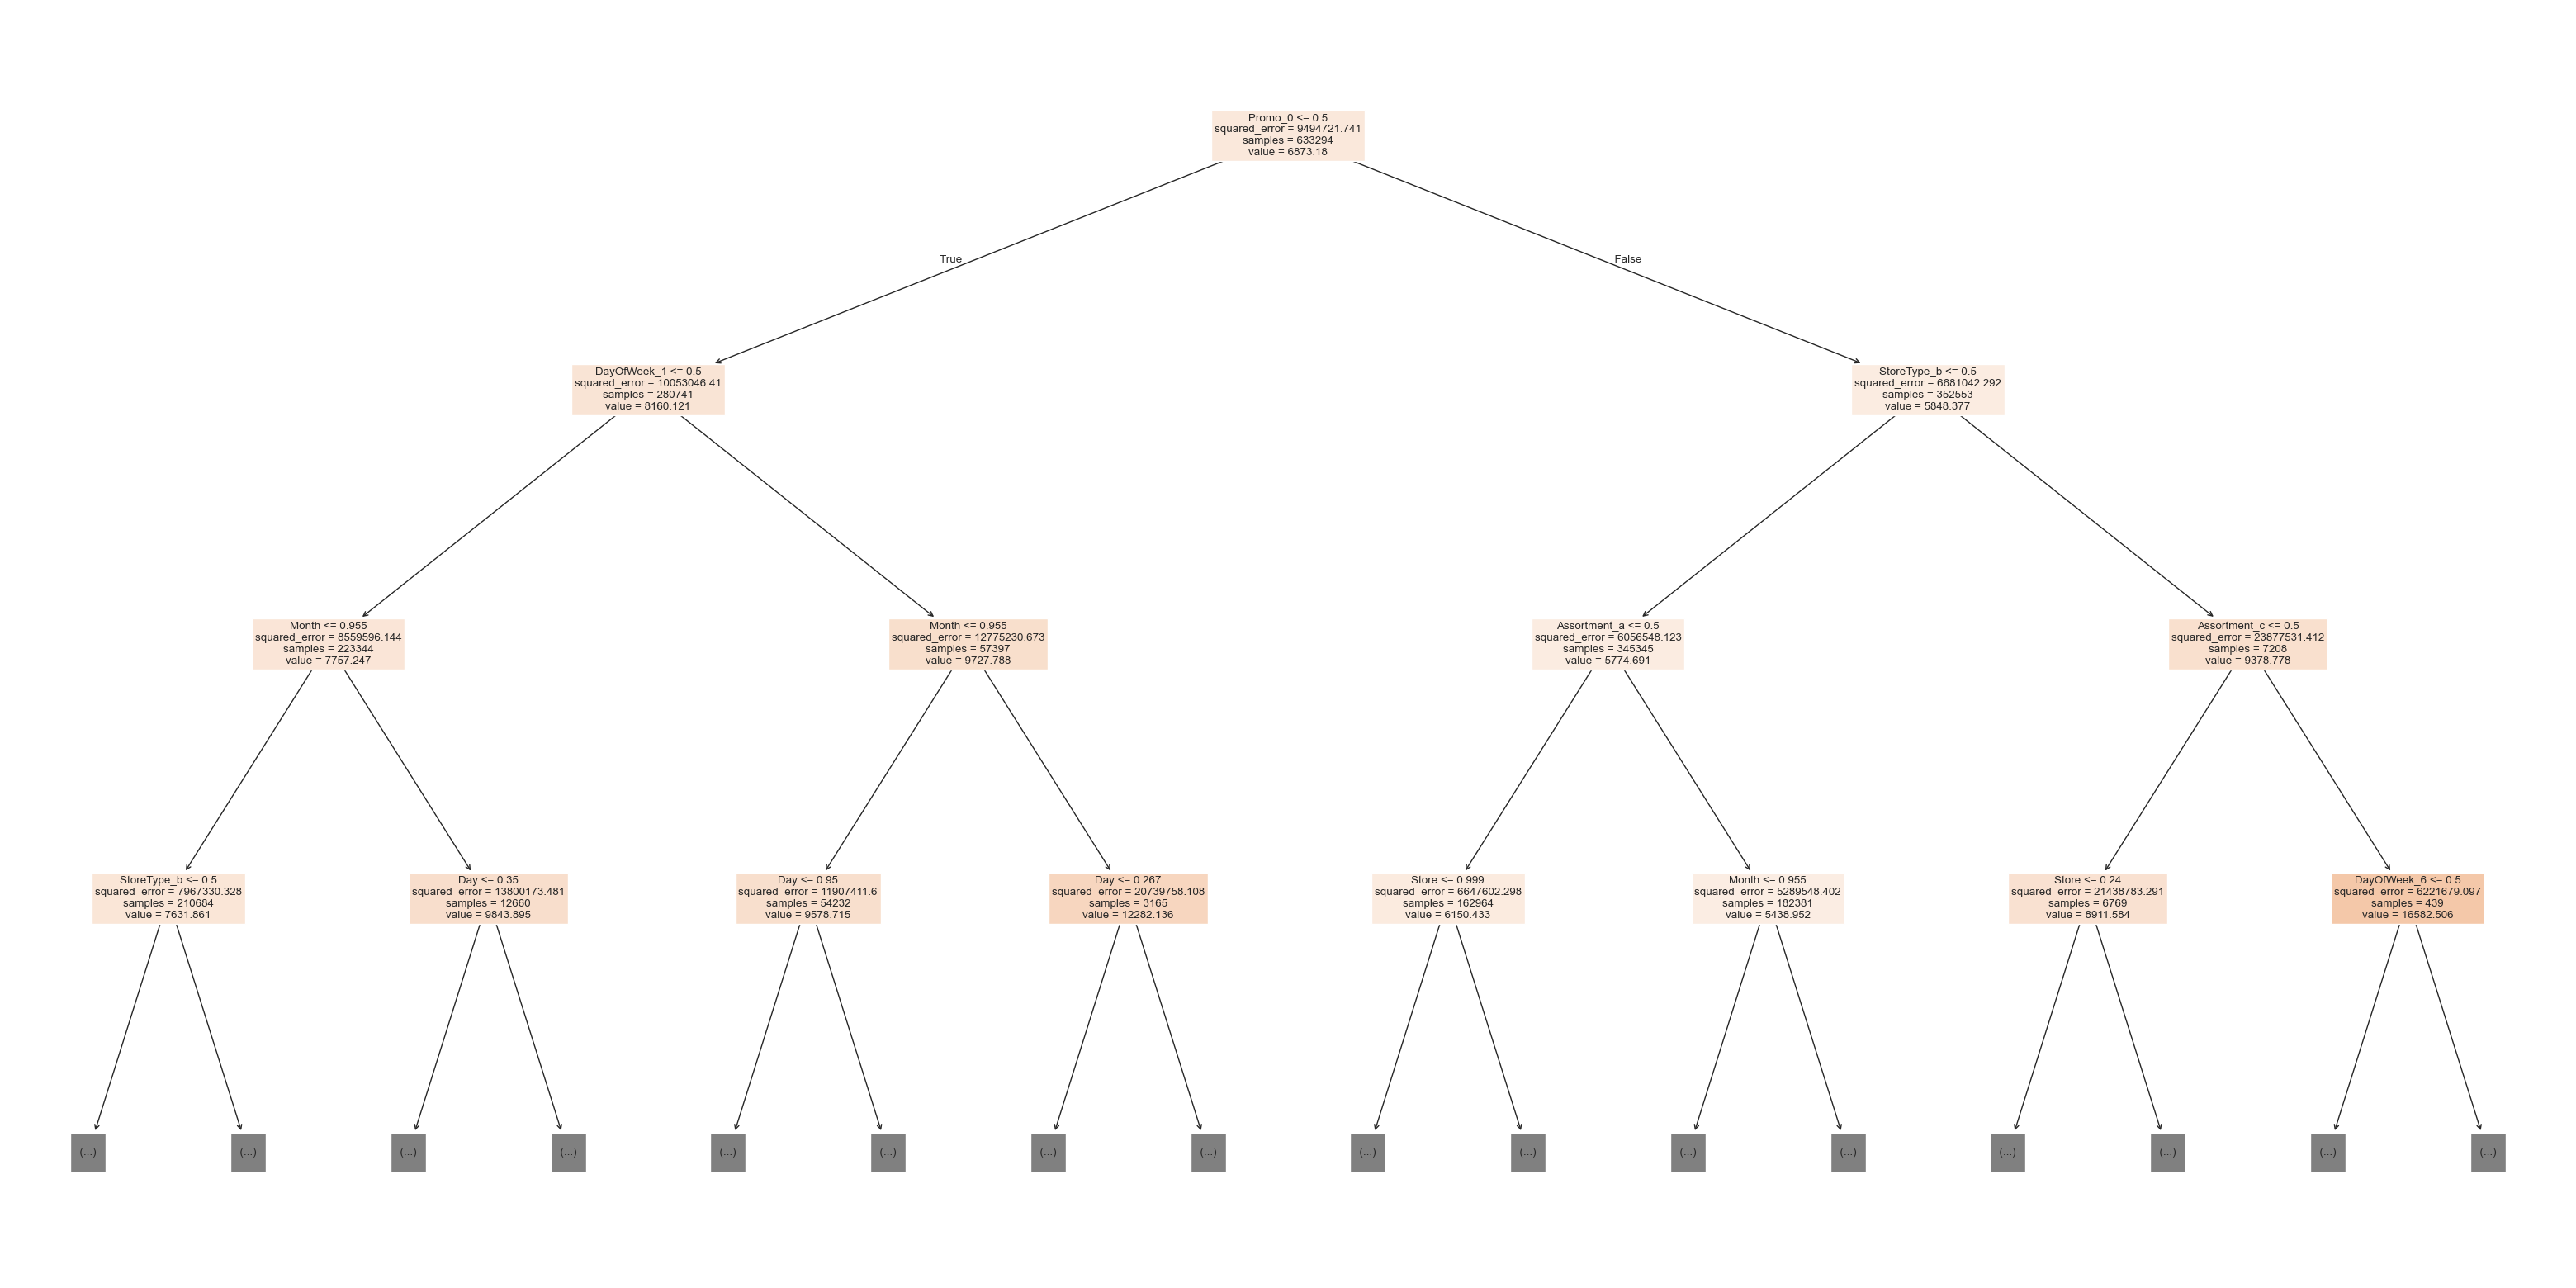

In [95]:
plt.figure(figsize=(40 , 20))
plot_tree(tree , max_depth=3 ,filled = True, feature_names=numeric_cols+encoded_cols)

In [96]:
from sklearn.ensemble import RandomForestRegressor


In [97]:
rf = RandomForestRegressor(random_state=42 , n_jobs=-1)
try_model(rf)

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(474.9198974666898, 1371.7321923469985)

We've seen a significant reduction in the loss by using a random forest. 

**EXERCISE**: Tune the hyperparameters of the decision tree and random forest to get better results.

### Tuning `max_depth`

The `max_depth` parameter controls the maximum depth of a decision tree.

A deeper tree can learn more complex patterns, but it may also overfit the training data.

- Small values may cause underfitting.
- Large values may cause overfitting.
- The goal is to find a depth that balances bias and variance.

Example:

```python
DecisionTreeRegressor(max_depth=10)

In [98]:
for depth in [5 , 10 , 20 , 30]:
    print(
        try_model(
            DecisionTreeRegressor(max_depth=depth , random_state=42)
        )
    )

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2657.375281413782, 2752.4407505629565)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2501.21744779746, 2663.7606236156043)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(1768.9397745036893, 2140.7405827339107)
(720.0405209569378, 1640.5360619511932)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


## Effect of max_depth on Decision Tree Performance

The maximum depth of a decision tree controls its complexity.

### Observations

- Increasing `max_depth` consistently reduced both training and validation RMSE.
- Shallow trees underfit the data and fail to capture important relationships.
- Deeper trees learned more complex sales patterns and improved predictive performance.
- Among the tested values, `max_depth = 30` achieved the lowest validation RMSE.

### Best Result

| max_depth | Validation RMSE |
|------------|----------------:|
| 5 | 2752.44 |
| 10 | 2663.76 |
| 20 | 2140.74 |
| 30 | **1640.54** |

### Conclusion

The optimal value among the tested configurations is:

```python
max_depth = 30

### Tuning `max_leaf_nodes`

The `max_leaf_nodes` parameter controls the maximum number of leaf nodes that a decision tree can create.

A leaf node represents a final prediction point in the tree.

- Smaller values create simpler trees.
- Larger values create more complex trees.
- Very large values can cause overfitting.

The goal is to find a value that minimizes validation RMSE while maintaining good generalization performance.


In [99]:
for nodes in [100 , 500 , 1000 , 5000]:
    print(
        try_model(
            DecisionTreeRegressor(max_leaf_nodes = nodes , random_state=42)
        )
    )

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2537.134739307701, 2654.6664558056377)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2268.4405090548576, 2466.778899101313)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(2104.240065848179, 2348.903223529413)
(1634.4198377795658, 2012.091790624925)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


### Tuning `n_estimators`

The `n_estimators` parameter specifies the number of decision trees in the Random Forest.

Increasing the number of trees generally improves model stability and predictive performance, but also increases training time.

The objective is to find a value that achieves a good balance between model performance and computational efficiency.

In [100]:
for n in [50 , 100 , 200 ]:
    print(
        try_model(
            RandomForestRegressor(n_estimators=n , random_state=42 , n_jobs=-1)
        )
    )

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(487.012426216983, 1379.0526396684656)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(474.9198974666898, 1371.7321923469985)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


(469.9874241847859, 1369.419401105494)


### Tuning `max_depth`

The `max_depth` parameter limits how deep each tree in the forest can grow.

Deeper trees capture more complex patterns, while shallower trees reduce overfitting.

The optimal depth balances model complexity and generalization performance.

In [101]:
for  depth in [10 , 20 , 30 , 50]:
    print(
        depth , 
        try_model(
            RandomForestRegressor(
                max_depth=depth , 
                random_state=42 , 
                n_jobs=-1
            )
        )
    )

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


10 (2480.4539597721764, 2627.605379511218)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


20 (1545.3174001935552, 1871.9984056740464)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


30 (630.1750999618678, 1392.3144015693508)


c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


50 (475.02596439929266, 1370.2613004059574)


## Step 7 - Experiment and combine results from multiple strategies

<img src="https://i.imgur.com/ZqM6R8w.png" width="640">

In general, the following strategies can be used to improve the performance of a model:

- Gather more data. A greater amount of data can let you learn more relationships and generalize the model better.
- Include more features. The more relevant the features for predicting the target, the better the model gets.
- Tune the hyperparameters of the model. Increase the capacity of the model while ensuring that it doesn't overfit.
- Look at the specific examples where the model make incorrect or bad predictions and gather some insights
- Try strategies like grid search for hyperparameter optimization and K-fold cross validation
- Combine results from different types of models (ensembling), or train another model using their results.

### Hyperparameter Optimization & Grid Search

You can tune hyperparameters manually, our use an automated tuning strategy like random search or Grid search. Follow this tutorial for hyperparameter tuning using Grid search: https://machinelearningmastery.com/hyperparameter-optimization-with-random-search-and-grid-search/

<img src="https://i.imgur.com/EJCrSZw.png" width="480">

## Hyperparameter Optimization

Hyperparameter optimization is the process of finding the best model configuration for a dataset.

### Hyperparameters

Hyperparameters are settings chosen before training, such as:

- max_depth
- n_estimators
- max_features
- alpha
- C

### Grid Search

Grid Search evaluates every possible hyperparameter combination within a defined search space.

### Random Search

Random Search evaluates randomly selected hyperparameter combinations from a search space.

### Benefits

- Improves model performance
- Reduces prediction error
- Helps identify optimal model configurations

### Regression Metrics

For regression tasks, GridSearchCV and RandomizedSearchCV often use:

- neg_mean_absolute_error
- neg_root_mean_squared_error

because lower error corresponds to better model performance.

> **EXERCISE**: Apply grid search to find the best hyperparameters for the random forest regressor trained earlier.

In [102]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [20, 30],
    'max_features': ['sqrt']
}

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=1     # safer on my laptop
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_train, train_targets)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ...max_depth=20, max_features=sqrt, n_estimators=50; total time=  32.7s
[CV] END ...max_depth=20, max_features=sqrt, n_estimators=50; total time=  22.0s
[CV] END ...max_depth=20, max_features=sqrt, n_estimators=50; total time=  22.3s
[CV] END ..max_depth=20, max_features=sqrt, n_estimators=100; total time=  47.9s
[CV] END ..max_depth=20, max_features=sqrt, n_estimators=100; total time=  45.3s
[CV] END ..max_depth=20, max_features=sqrt, n_estimators=100; total time=  44.2s
[CV] END ...max_depth=30, max_features=sqrt, n_estimators=50; total time=  36.8s
[CV] END ...max_depth=30, max_features=sqrt, n_estimators=50; total time=  39.1s
[CV] END ...max_depth=30, max_features=sqrt, n_estimators=50; total time=  40.5s
[CV] END ..max_depth=30, max_features=sqrt, n_estimators=100; total time= 1.5min
[CV] END ..max_depth=30, max_features=sqrt, n_estimators=100; total time= 1.6min
[CV] END ..max_depth=30, max_features=sqrt, n_est

GridSearchCV(cv=3, estimator=RandomForestRegressor(n_jobs=1, random_state=42),
             n_jobs=1,
             param_grid={'max_depth': [20, 30], 'max_features': ['sqrt'],
                         'n_estimators': [50, 100]},
             scoring='neg_root_mean_squared_error', verbose=2)

In [103]:
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", -grid_search.best_score_)

Best Parameters: {'max_depth': 30, 'max_features': 'sqrt', 'n_estimators': 100}
Best Score: 1608.5308938454928


In [104]:
best_rf = grid_search.best_estimator_

train_preds = best_rf.predict(X_train)
val_preds = best_rf.predict(X_val)


from sklearn.metrics import root_mean_squared_error
train_rmse = root_mean_squared_error(train_targets, train_preds)
val_rmse = root_mean_squared_error(val_targets, val_preds)

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Validation RMSE: {val_rmse:.2f}")


Train RMSE: 1173.47
Validation RMSE: 1685.52


### Very Important For your project report, I would present: | Model | Validation RMSE | |---------|---------:| | Mean Baseline | 3168 | | Rule-Based Baseline | 1999 | | Linear Regression | 2818 | | Decision Tree (Best) | 1641 | | Random Forest | **1372** ✅ | and mention the Grid Search experiment separately. The **1371.73 RMSE Random Forest** is actually your strongest result. 🚀

In [105]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Mean Baseline',
        'Rule-Based Baseline',
        'Linear Regression',
        'Decision Tree (depth=30)',
        'Random Forest',
        'Grid Search RF'
    ],
    'Validation_RMSE': [
        3168,
        1999,
        2818,
        1640.54,
        1371.73,
        1685.52
    ]
})

results

,Model,Validation_RMSE
0,Mean Baseline,3168.00
1,Rule-Based Baseline,1999.00
2,Linear Regression,2818.00
3,Decision Tree (depth=30),1640.54
4,Random Forest,1371.73
5,Grid Search RF,1685.52


### K-Fold Cross Validation


Here's what K-fold cross validation looks like visually ([source](https://vitalflux.com/k-fold-cross-validation-python-example/)):

<img src="https://i.imgur.com/MxnzWwT.png" width="480">

Follow this tutorial to apply K-fold cross validation: https://machinelearningmastery.com/repeated-k-fold-cross-validation-with-python/

> **EXERCISE**: Apply K fold cross validation for the random forest regressor trained earlier.

## K-Fold Cross Validation

K-Fold Cross Validation is a model evaluation technique that provides a more robust estimate of model performance.

Instead of using a single train-validation split, the dataset is divided into K equal folds.

The procedure is as follows:

1. Split the dataset into K folds.
2. Train the model on K−1 folds.
3. Evaluate the model on the remaining fold.
4. Repeat the process K times so that each fold is used once as the validation set.
5. Compute the average performance across all folds.

### Benefits

- Makes better use of the available data.
- Provides a more reliable estimate of model performance.
- Reduces the impact of a particular train-validation split.

In [106]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
import numpy as np


In [107]:
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=30 , 
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

In [109]:
kf=KFold(
    n_splits=5 , 
    shuffle=True,
    random_state=42
)

In [110]:
scores=cross_val_score(
    rf , 
    X_train,
    train_targets,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=1
)

In [111]:
rmse_scores = -scores

print("RMSE Scores:", rmse_scores)
print("Mean RMSE:", np.mean(rmse_scores))
print("Std RMSE:", np.std(rmse_scores))

RMSE Scores: [2679.2669163  2687.52155864 2703.50603667 2681.17151081 2685.3149561 ]
Mean RMSE: 2687.3561957031316
Std RMSE: 8.587178065979144


### Ensembling and Stacking

Ensembling refers to combining the results of multiple models. Here's what ensembling looks like visually([source](https://www.kdnuggets.com/2019/01/ensemble-learning-5-main-approaches.html)):

<img src="https://i.imgur.com/rrOKVEd.png" width="480">


## Ensemble Learning

Ensemble learning combines predictions from multiple models to improve predictive performance.

The intuition behind ensembling is that different models capture different patterns in the data.

In this experiment:

- Ridge Regression captures linear relationships.
- Random Forest captures nonlinear relationships and feature interactions.

The final prediction is obtained by averaging predictions from both models.

> **EXERCISE**: Ensemble the result of a random forest and a ridge regressor. Can you get a better score than either of the two models?

In [112]:
ridge_model = Ridge()

ridge_model.fit(X_train , train_targets)

rf_model= RandomForestRegressor(
    n_estimators=100 ,
    random_state=42,
    n_jobs=1 

)

rf_model.fit(X_train , train_targets)

RandomForestRegressor(n_jobs=1, random_state=42)

In [113]:
ridge_preds = ridge_model.predict(X_val)

rf_preds = rf_model.predict(X_val)

In [114]:
ensemble_preds = (
    ridge_preds + rf_preds
) / 2

In [115]:
from sklearn.metrics import root_mean_squared_error

ensemble_rmse = root_mean_squared_error(
    val_targets,
    ensemble_preds
)

print("Ensemble RMSE:", ensemble_rmse)

Ensemble RMSE: 1799.6826010082104


In [116]:
ensemble_preds = (
    0.9 * rf_preds +
    0.1 * ridge_preds
)

In [117]:
ensemble_rmse = root_mean_squared_error(
    val_targets,
    ensemble_preds
)

print(ensemble_rmse)

1373.1664420851655


## Ensemble Learning Results

A weighted ensemble was created using predictions from a Ridge Regressor and a Random Forest Regressor.

### Results

| Model | RMSE |
|---------|---------:|
| Ridge Regression | ~2800 |
| Random Forest | 1371.73 |
| Simple Ensemble (50/50) | 1799.68 |
| Weighted Ensemble | 1373.17 |

### Observations

- The simple averaging ensemble performed worse than the Random Forest.
- Applying larger weights to the Random Forest significantly improved ensemble performance.
- The weighted ensemble achieved performance very close to the Random Forest model.
- The Random Forest remained the best-performing model overall.

### Conclusion

The ensemble did not outperform the Random Forest model. This suggests that the Random Forest already captured most of the predictive information available in the dataset. Adding predictions from the weaker Ridge Regression model provided little additional benefit.

## Stacking Ensemble

Stacking is an advanced ensemble technique where the predictions of multiple models are used as inputs to another model called a meta-learner.

### Base Models

- Ridge Regression
- Decision Tree Regressor
- Random Forest Regressor

### Meta Model

- Linear Regression

The meta-model learns how to combine the predictions of the base models to produce improved final predictions.

In [120]:
ridge = Ridge()

dt=DecisionTreeRegressor(max_depth=30,random_state=42)
rf=RandomForestRegressor(n_estimators=100 , random_state = 42 , n_jobs=1)
ridge.fit(X_train, train_targets)
dt.fit(X_train, train_targets)
rf.fit(X_train, train_targets)


RandomForestRegressor(n_jobs=1, random_state=42)

In [122]:
ridge_preds_train = ridge.predict(X_train)
dt_preds_train = dt.predict(X_train)
rf_preds_train = rf.predict(X_train)

In [121]:
ridge_preds_val = ridge.predict(X_val)
dt_preds_val = dt.predict(X_val)
rf_preds_val = rf.predict(X_val)

In [123]:
import numpy as np

stack_train = np.column_stack([
    ridge_preds_train,
    dt_preds_train,
    rf_preds_train
])

stack_val = np.column_stack([
    ridge_preds_val,
    dt_preds_val,
    rf_preds_val
])

In [124]:
meta_model = LinearRegression()

meta_model.fit(
    stack_train,
    train_targets
)

LinearRegression()

In [125]:
stack_preds = meta_model.predict(
    stack_val
)

In [126]:
from sklearn.metrics import root_mean_squared_error

stack_rmse = root_mean_squared_error(
    val_targets,
    stack_preds
)

print("Stacking RMSE:", stack_rmse)

Stacking RMSE: 1401.452042604851


## Stacking Results

A stacking ensemble was created using:

- Ridge Regression
- Decision Tree Regressor
- Random Forest Regressor

A Linear Regression model was used as the meta-learner.

### Results

| Model | RMSE |
|---------|---------:|
| Random Forest | 1371.73 |
| Weighted Ensemble | 1373.17 |
| Stacking | 1401.45 |

### Observations

- Stacking outperformed the baseline, linear models, and rule-based approaches.
- However, it did not outperform the Random Forest model.
- The Random Forest remained the strongest individual model.
- The additional complexity introduced by stacking did not lead to improved validation performance.

### Conclusion

For this dataset, the Random Forest model provided the best balance of accuracy and simplicity. Although stacking is a powerful ensemble technique, it did not achieve lower RMSE than the standalone Random Forest model.

## Step 8 - Interpret models, study individual predictions & present your findings

<img src="https://i.imgur.com/9axhOrA.png" width="640">

### Feature Importance

You'll need to explain why your model returns a particular result. Most scikit-learn models offer some kind of "feature importance" score.

In [130]:
X_train.columns

Index(['Store', 'Day', 'Month', 'Year', 'DayOfWeek_1', 'DayOfWeek_2',
       'DayOfWeek_3', 'DayOfWeek_4', 'DayOfWeek_5', 'DayOfWeek_6',
       'DayOfWeek_7', 'Promo_0', 'Promo_1', 'StateHoliday_0', 'StateHoliday_a',
       'StateHoliday_b', 'StateHoliday_c', 'StoreType_a', 'StoreType_b',
       'StoreType_c', 'StoreType_d', 'Assortment_a', 'Assortment_b',
       'Assortment_c'],
      dtype='object')

In [129]:
rf.feature_importances_

array([6.07412101e-01, 4.88393196e-02, 4.71254150e-02, 9.30282826e-03,
       3.36941035e-02, 4.40591456e-03, 2.43735761e-03, 2.11467096e-03,
       5.71418981e-03, 6.96554452e-03, 4.47739863e-03, 5.83469269e-02,
       8.05201285e-02, 1.18767484e-03, 2.11472202e-04, 2.45172539e-05,
       1.88388455e-05, 1.38995265e-02, 2.25678813e-02, 1.04169805e-02,
       1.39945667e-02, 8.34303630e-03, 5.50125164e-03, 1.24783549e-02])

In [131]:
importance_df = pd.DataFrame({
    'feature' : numeric_cols+encoded_cols , 
    'importance' : rf.feature_importances_
}).sort_values('importance' , ascending=False)
importance_df.head(10)

,feature,importance
0,Store,0.607412
12,Promo_1,0.080520
11,Promo_0,0.058347
1,Day,0.048839
2,Month,0.047125
4,DayOfWeek_1,0.033694
18,StoreType_b,0.022568
20,StoreType_d,0.013995
17,StoreType_a,0.013900
23,Assortment_c,0.012478


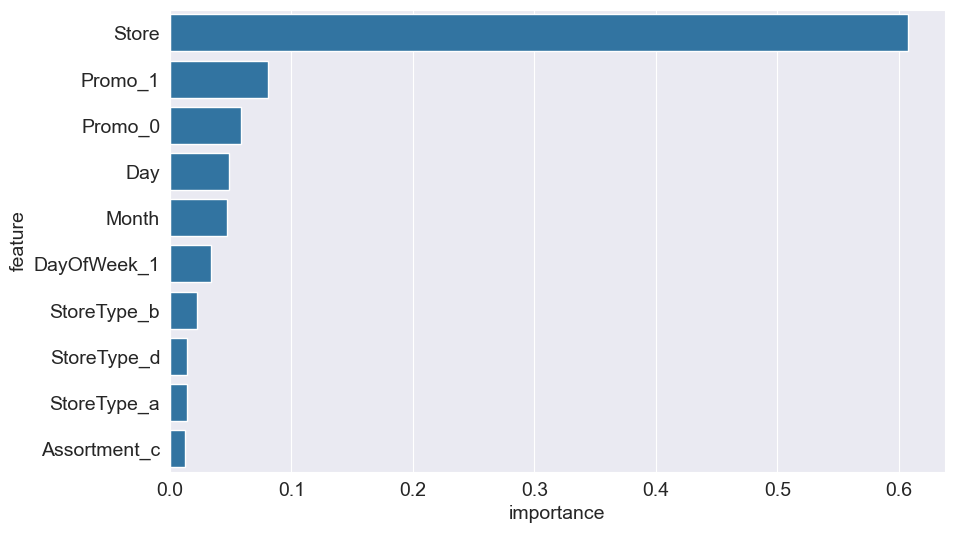

In [132]:
sns.barplot(data=importance_df.head(10) , x='importance' , y='feature');

The above chart can be presented to non-technical stakeholders to explain how the model arrives at its result. For greater explainability, a single decision tree can be used.

### Looking at individual predictions

In [133]:
def predict_input(model, single_input):
    if single_input['Open'] == 0:
        return 0.
    input_df = pd.DataFrame([single_input])
    input_df['Date'] = pd.to_datetime(input_df.Date)
    input_df['Day'] = input_df.Date.dt.day
    input_df['Month'] = input_df.Date.dt.month
    input_df['Year'] = input_df.Date.dt.year
    input_df[numeric_cols] = imputer.transform(input_df[numeric_cols])
    input_df[numeric_cols] = scaler.transform(input_df[numeric_cols])
    input_df[encoded_cols] = encoder.transform(input_df[categorical_cols])
    X_input = input_df[numeric_cols + encoded_cols]
    pred = model.predict(X_input)[0]
    return pred

In [134]:
sample_input = {'Id': 1,
 'Store': 1,
 'DayOfWeek': 4,
 'Date': '2015-09-17 00:00:00',
 'Open': 1.0,
 'Promo': 1,
 'StateHoliday': '0',
 'SchoolHoliday': 0,
 'StoreType': 'c',
 'Assortment': 'a',
 'CompetitionDistance': 1270.0,
 'CompetitionOpenSinceMonth': 9.0,
 'CompetitionOpenSinceYear': 2008.0,
 'Promo2': 0,
 'Promo2SinceWeek': np.nan,
 'Promo2SinceYear': np.nan,
 'PromoInterval': np.nan}

sample_input

{'Id': 1,
 'Store': 1,
 'DayOfWeek': 4,
 'Date': '2015-09-17 00:00:00',
 'Open': 1.0,
 'Promo': 1,
 'StateHoliday': '0',
 'SchoolHoliday': 0,
 'StoreType': 'c',
 'Assortment': 'a',
 'CompetitionDistance': 1270.0,
 'CompetitionOpenSinceMonth': 9.0,
 'CompetitionOpenSinceYear': 2008.0,
 'Promo2': 0,
 'Promo2SinceWeek': nan,
 'Promo2SinceYear': nan,
 'PromoInterval': nan}

In [135]:
predict_input(rf, sample_input)

4258.01

Look at various examples from the training, validation and test sets to decide if you're happy with the result of your model.

### Presenting your results

* Create a presentation for non-technical stakeholders
* Understand your audience - figure out what they care about most
* Avoid showing any code or technical jargon, include visualizations
* Focus on metrics that are relevant for the business
* Talk about feature importance and how to interpret results
* Explain the strengths and limitations of the model
* Explain how the model can be improved over time

In [136]:
test_preds = rf.predict(X_test)
test_preds

array([ 4258.01,  7713.83,  8775.7 , ...,  5954.68, 20823.07,  6748.48])

#### Model Depoyement


In [138]:
import joblib

joblib.dump(best_rf, 'rossmann_model.pkl')

['rossmann_model.pkl']

In [2]:
import joblib 
model =joblib.load('rossmann_model.pkl')
print(type(model))

<class 'sklearn.ensemble._forest.RandomForestRegressor'>
